In [6]:
import os

# Set the folder path
census_folder = "census_data"

# List all files inside it
for file in os.listdir(census_folder):
    print(file)

Datensatzbeschreibung_Bevoelkerungszahl_Gitterzellen.xlsx
Zensus2022_Bevoelkerungszahl_100m-Gitter.csv
Zensus2022_Bevoelkerungszahl_10km-Gitter.csv
Zensus2022_Bevoelkerungszahl_1km-Gitter.csv


In [7]:
import pandas as pd

# Load the Excel dataset description
census_description = pd.ExcelFile(
    "census_data/Datensatzbeschreibung_Bevoelkerungszahl_Gitterzellen.xlsx"
)

# List the available sheets
print(census_description.sheet_names)

['Titel', 'Inhaltsübersicht', 'Impressum', 'Erläuterungen', 'Merkmalsdefinitionen', 'Erläuterung zu CSV pro 100 m', 'Erläuterung zu CSV pro 1 km', 'Erläuterung zu CSV pro 10 km']


In [8]:
# Read the two relevant documentation sheets
features = pd.read_excel(
    "census_data/Datensatzbeschreibung_Bevoelkerungszahl_Gitterzellen.xlsx",
    sheet_name="Merkmalsdefinitionen",
    header=None
)

grid_100m_info = pd.read_excel(
    "census_data/Datensatzbeschreibung_Bevoelkerungszahl_Gitterzellen.xlsx",
    sheet_name="Erläuterung zu CSV pro 100 m",
    header=None
)

# Display the contents
print("MERKMALSDEFINITIONEN")
display(features)

print("100 M GRID CSV EXPLANATION")
display(grid_100m_info)

MERKMALSDEFINITIONEN


,0,1
0,zur Inhaltsübersicht,NaN
1,NaN,Merkmalsdefinitionen zu CSV-Tabellen
2,NaN,NaN
3,NaN,"Der Gitter-Identifikator (Gitter_ID_10km, Gitt..."
4,NaN,NaN
5,NaN,Jede Einwohnerin / jeder Einwohner ist einer A...
6,NaN,NaN
7,NaN,In bundesweit 163 Gemeinden konnten für insges...


100 M GRID CSV EXPLANATION


,0,1,2
0,zur Inhaltsübersicht,NaN,NaN
1,NaN,Erläuterung zu CSV-Tabelle - Bevölkerungszahl ...,NaN
2,NaN,NaN,NaN
3,NaN,Für die Weiterverarbeitung stellen wir die Inh...,NaN
4,NaN,Für die weitere Verwendung der Daten finden Si...,NaN
5,NaN,NaN,NaN
6,NaN,Zensus2022_Bevoelkerungszahl_100m-Gitter.csv,Ergebnisse des Zensus 2022 Tabelle Bevölkerung...
7,NaN,NaN,NaN
8,NaN,Zeilenaufbau,NaN
9,NaN,NaN,NaN


In [10]:
# Check the dimensions and full contents
print("Features shape:", features.shape)
display(features.to_string(index=True))

print("100 m grid explanation shape:", grid_100m_info.shape)
display(grid_100m_info.to_string(index=True))

Features shape: (8, 2)


'                      0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        1\n0  zur Inhaltsübersicht                                                                                                                                                                                                                                                                                                                                                              

100 m grid explanation shape: (22, 3)


'                       0                                                                                                                                                                                                                                                                                                                                              1                                                                                                                                                                                                                                                                                                                                                                                                                          2\n0   zur Inhaltsübersicht                                                                                                                                                                                                           

In [11]:
# Read the first five rows of the 100 m population grid
census_100m_sample = pd.read_csv(
    "census_data/Zensus2022_Bevoelkerungszahl_100m-Gitter.csv",
    sep=";",
    nrows=5
)

# Inspect the sample
display(census_100m_sample)

# Check column names and data types
print(census_100m_sample.dtypes)

,GITTER_ID_100m,x_mp_100m,y_mp_100m,Einwohner
0,CRS3035RES100mN2689100E4337000,4337050,2689150,4
1,CRS3035RES100mN2689100E4341100,4341150,2689150,11
2,CRS3035RES100mN2690800E4341200,4341250,2690850,4
3,CRS3035RES100mN2691200E4341200,4341250,2691250,12
4,CRS3035RES100mN2691300E4341200,4341250,2691350,3


GITTER_ID_100m      str
x_mp_100m         int64
y_mp_100m         int64
Einwohner         int64
dtype: object


In [14]:
import geopandas as gpd
import pandas as pd
import os

# Set the path to your LOR GeoJSON file
lor_file = "satellite_data/berlin_lor_2021.geojson"

# Load the neighbourhood boundaries
lor_tree_crs = gpd.read_file(lor_file)

# Inspect the dataset
print("Shape:", lor_tree_crs.shape)
print("CRS:", lor_tree_crs.crs)
print("Columns:", lor_tree_crs.columns.tolist())

display(lor_tree_crs.head())

Shape: (143, 9)
CRS: EPSG:4326
Columns: ['id', 'bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt', 'stand', 'geometry']


,id,bzr_id,bzr_name,pgr_id,pgr_name,bez,finhalt,stand,geometry
0,b_lor_bzr_2021.011001,011001,Tiergarten Süd,0110,Zentrum,01 - Mitte,5.172481e+06,01.12.2021,"MULTIPOLYGON (((13.33601 52.51379, 13.33587 52..."
1,b_lor_bzr_2021.011002,011002,Regierungsviertel,0110,Zentrum,01 - Mitte,2.695511e+06,01.01.2021,"MULTIPOLYGON (((13.3765 52.51602, 13.37651 52...."
2,b_lor_bzr_2021.011003,011003,Alexanderplatz,0110,Zentrum,01 - Mitte,6.228825e+06,01.01.2021,"MULTIPOLYGON (((13.37357 52.52788, 13.37364 52..."
3,b_lor_bzr_2021.011004,011004,Brunnenstraße Süd,0110,Zentrum,01 - Mitte,1.755196e+06,01.01.2021,"MULTIPOLYGON (((13.39586 52.53809, 13.39569 52..."
4,b_lor_bzr_2021.012005,012005,Moabit West,0120,Moabit,01 - Mitte,4.305047e+06,01.01.2021,"MULTIPOLYGON (((13.33422 52.51677, 13.33431 52..."


In [15]:
# Check neighbourhood identifiers
print("Unique neighbourhoods:", lor_tree_crs["bzr_id"].nunique())

# Check for missing identifiers
print("Missing bzr_id:", lor_tree_crs["bzr_id"].isna().sum())
print("Missing bzr_name:", lor_tree_crs["bzr_name"].isna().sum())

# Check geometry
print("Geometry types:", lor_tree_crs.geometry.geom_type.unique())
print("Missing geometries:", lor_tree_crs.geometry.isna().sum())
print("Invalid geometries:", (~lor_tree_crs.geometry.is_valid).sum())

# Check spatial extent
print("Bounds:", lor_tree_crs.total_bounds)

Unique neighbourhoods: 143
Missing bzr_id: 0
Missing bzr_name: 0
Geometry types: <ArrowStringArray>
['MultiPolygon']
Length: 1, dtype: str
Missing geometries: 0
Invalid geometries: 0
Bounds: [13.0883476  52.33824557 13.76115913 52.6755077 ]


In [16]:
# Reproject neighbourhood boundaries if necessary
if lor_tree_crs.crs != "EPSG:3035":
    lor_tree_crs = lor_tree_crs.to_crs("EPSG:3035")

print("Final CRS:", lor_tree_crs.crs)

Final CRS: EPSG:3035


In [17]:
# Check the population CSV file size
file_path = "census_data/Zensus2022_Bevoelkerungszahl_100m-Gitter.csv"

file_size_mb = os.path.getsize(file_path) / (1024 ** 2)
print(f"File size: {file_size_mb:.2f} MB")

# Load the population grid
census_100m = pd.read_csv(
    file_path,
    sep=";",
    dtype={"GITTER_ID_100m": str}
)

# Inspect the dataset
print("\nShape:", census_100m.shape)
print("\nData types:")
print(census_100m.dtypes)

print("\nFirst rows:")
display(census_100m.head())

# Check missing values
print("\nMissing values:")
print(census_100m.isna().sum())

# Check special or non-numeric population values
print("\nPopulation values that cannot be converted to numbers:")
population_numeric = pd.to_numeric(
    census_100m["Einwohner"],
    errors="coerce"
)

print(population_numeric.isna().sum())

File size: 146.30 MB

Shape: (3088037, 4)

Data types:
GITTER_ID_100m      str
x_mp_100m         int64
y_mp_100m         int64
Einwohner         int64
dtype: object

First rows:


,GITTER_ID_100m,x_mp_100m,y_mp_100m,Einwohner
0,CRS3035RES100mN2689100E4337000,4337050,2689150,4
1,CRS3035RES100mN2689100E4341100,4341150,2689150,11
2,CRS3035RES100mN2690800E4341200,4341250,2690850,4
3,CRS3035RES100mN2691200E4341200,4341250,2691250,12
4,CRS3035RES100mN2691300E4341200,4341250,2691350,3



Missing values:
GITTER_ID_100m    0
x_mp_100m         0
y_mp_100m         0
Einwohner         0
dtype: int64

Population values that cannot be converted to numbers:
0


In [18]:
# Get the bounding box of the 143 neighbourhoods
minx, miny, maxx, maxy = lor_tree_crs.total_bounds

# Keep grid-cell centres inside the Berlin bounding box
census_berlin_candidates = census_100m[
    census_100m["x_mp_100m"].between(minx, maxx)
    & census_100m["y_mp_100m"].between(miny, maxy)
].copy()

# Inspect the filtered dataset
print("Original grid cells:", len(census_100m))
print("Berlin bounding-box candidates:", len(census_berlin_candidates))

print("\nCoordinate ranges:")
print(
    "X:", census_berlin_candidates["x_mp_100m"].min(),
    "to", census_berlin_candidates["x_mp_100m"].max()
)
print(
    "Y:", census_berlin_candidates["y_mp_100m"].min(),
    "to", census_berlin_candidates["y_mp_100m"].max()
)

print("\nPopulation in bounding-box candidates:",
      census_berlin_candidates["Einwohner"].sum())

print("Zero-population cells:",
      (census_berlin_candidates["Einwohner"] == 0).sum())

Original grid cells: 3088037
Berlin bounding-box candidates: 57811

Coordinate ranges:
X: 4531050 to 4576650
Y: 3253950 to 3290750

Population in bounding-box candidates: 4061743
Zero-population cells: 0


In [19]:
# Convert grid-cell centre coordinates into spatial points
census_points = gpd.GeoDataFrame(
    census_berlin_candidates.copy(),
    geometry=gpd.points_from_xy(
        census_berlin_candidates["x_mp_100m"],
        census_berlin_candidates["y_mp_100m"]
    ),
    crs="EPSG:3035"
)

# Keep only the necessary neighbourhood columns
lor_for_join = lor_tree_crs[
    ["bzr_id", "bzr_name", "bez", "geometry"]
].copy()

# Assign each population grid cell to a neighbourhood
census_berlin_joined = gpd.sjoin(
    census_points,
    lor_for_join,
    how="left",
    predicate="within"
)

# Check the spatial join
print("Joined rows:", len(census_berlin_joined))

print(
    "Cells without a neighbourhood:",
    census_berlin_joined["bzr_id"].isna().sum()
)

print(
    "Duplicate grid-cell assignments:",
    census_berlin_joined["GITTER_ID_100m"].duplicated().sum()
)

print(
    "Population assigned to neighbourhoods:",
    census_berlin_joined["Einwohner"].sum()
)

Joined rows: 57811
Cells without a neighbourhood: 17149
Duplicate grid-cell assignments: 0
Population assigned to neighbourhoods: 4061743


In [20]:
#investigating the cells without neighbourhood

# Separate assigned and unassigned grid cells
assigned_cells = census_berlin_joined[
    census_berlin_joined["bzr_id"].notna()
].copy()

unassigned_cells = census_berlin_joined[
    census_berlin_joined["bzr_id"].isna()
].copy()

# Compare row counts and population totals
print("Assigned cells:", len(assigned_cells))
print("Unassigned cells:", len(unassigned_cells))

print("\nAssigned population:")
print(assigned_cells["Einwohner"].sum())

print("\nUnassigned population:")
print(unassigned_cells["Einwohner"].sum())

print("\nTotal population in candidates:")
print(census_berlin_candidates["Einwohner"].sum())

# Check whether the population totals reconcile
print(
    "\nReconciliation:",
    assigned_cells["Einwohner"].sum()
    + unassigned_cells["Einwohner"].sum()
)

Assigned cells: 40662
Unassigned cells: 17149

Assigned population:
3595261

Unassigned population:
466482

Total population in candidates:
4061743

Reconciliation: 4061743


## Checking below the more updated Berlin Population CSV file since it's dated 2025 and contains population per Kiez/Neighbourhood

In [21]:
import pandas as pd

# Set the path to your downloaded CSV
population_file = "census_data/berlin_population_2025.csv"

# Load the population statistics
population_2025 = pd.read_csv(
    population_file,
    sep=";",
    dtype={
        "RAUMID": str,
        "BEZ": str,
        "PGR": str,
        "BZR": str,
        "PLR": str,
        "BEZPGR": str
    }
)

# Inspect the dataset
print("Shape:", population_2025.shape)
print("\nColumns:")
print(population_2025.columns.tolist())

print("\nData types:")
print(population_2025.dtypes)

display(population_2025.head())

Shape: (542, 51)

Columns:
['ZEIT', 'RAUMID', 'BEZ', 'PGR', 'BZR', 'PLR', 'BEZPGR', 'E_E', 'E_EM', 'E_EW', 'E_E00_01', 'E_E01_02', 'E_E02_03', 'E_E03_05', 'E_E05_06', 'E_E06_07', 'E_E07_08', 'E_E08_10', 'E_E10_12', 'E_E12_14', 'E_E14_15', 'E_E15_18', 'E_E18_21', 'E_E21_25', 'E_E25_27', 'E_E27_30', 'E_E30_35', 'E_E35_40', 'E_E40_45', 'E_E45_50', 'E_E50_55', 'E_E55_60', 'E_E60_63', 'E_E63_65', 'E_E65_67', 'E_E67_70', 'E_E70_75', 'E_E75_80', 'E_E80_85', 'E_E85_90', 'E_E90_95', 'E_E95_110', 'E_EU1', 'E_E1U6', 'E_E6U15', 'E_E15U18', 'E_E18U25', 'E_E25U55', 'E_E55U65', 'E_E65U80', 'E_E80U110']

Data types:
ZEIT           int64
RAUMID           str
BEZ              str
PGR              str
BZR              str
PLR              str
BEZPGR           str
E_E          float64
E_EM         float64
E_EW         float64
E_E00_01     float64
E_E01_02     float64
E_E02_03     float64
E_E03_05     float64
E_E05_06     float64
E_E06_07     float64
E_E07_08     float64
E_E08_10     float64
E_E10_12     f

,ZEIT,RAUMID,BEZ,PGR,BZR,PLR,BEZPGR,E_E,E_EM,E_EW,...,E_E95_110,E_EU1,E_E1U6,E_E6U15,E_E15U18,E_E18U25,E_E25U55,E_E55U65,E_E65U80,E_E80U110
0,202512,01100101,01,10,01,01,0110,3469.0,1803.0,1666.0,...,4.0,21.0,113.0,190.0,58.0,273.0,1739.0,375.0,451.0,249.0
1,202512,01100102,01,10,01,02,0110,2082.0,1118.0,964.0,...,4.0,12.0,95.0,114.0,29.0,124.0,1118.0,299.0,214.0,77.0
2,202512,01100103,01,10,01,03,0110,5832.0,3055.0,2777.0,...,14.0,39.0,211.0,370.0,124.0,443.0,2863.0,676.0,812.0,294.0
3,202512,01100104,01,10,01,04,0110,4966.0,2608.0,2358.0,...,3.0,44.0,241.0,359.0,137.0,489.0,2644.0,575.0,386.0,91.0
4,202512,01100205,01,10,02,05,0110,2950.0,1536.0,1414.0,...,4.0,16.0,99.0,172.0,60.0,248.0,1517.0,345.0,354.0,139.0


In [22]:
# Check the reference period
print("Reference periods:")
print(population_2025["ZEIT"].unique())

# Check the geographic levels
print("\nUnique districts:", population_2025["BEZ"].nunique())
print("Unique Prognoseräume:", population_2025["BEZPGR"].nunique())
print("Unique Bezirksregion codes:", population_2025[["BEZ", "BZR"]].drop_duplicates().shape[0])
print("Unique Planungsräume:", population_2025["RAUMID"].nunique())

# Check for missing values
print("\nMissing values:")
print(population_2025.isna().sum().head(15))

Reference periods:
[202512]

Unique districts: 12
Unique Prognoseräume: 58
Unique Bezirksregion codes: 143
Unique Planungsräume: 542

Missing values:
ZEIT        0
RAUMID      0
BEZ         0
PGR         0
BZR         0
PLR         0
BEZPGR      2
E_E         2
E_EM        2
E_EW        2
E_E00_01    2
E_E01_02    2
E_E02_03    2
E_E03_05    2
E_E05_06    2
dtype: int64


In [23]:
# Find rows containing at least one missing value
missing_rows = population_2025[
    population_2025.isna().any(axis=1)
]

print("Number of incomplete rows:", len(missing_rows))

# Display the incomplete records
display(missing_rows.T)

# Check how many values are missing in each incomplete row
print("\nMissing values per row:")
print(missing_rows.isna().sum(axis=1))

Number of incomplete rows: 2


,115,260
ZEIT,202512,202512
RAUMID,03400831,06200418
BEZ,03,06
PGR,40,20
BZR,08,04
PLR,31,18
BEZPGR,NaN,NaN
E_E,NaN,NaN
E_EM,NaN,NaN
E_EW,NaN,NaN



Missing values per row:
115    45
260    45
dtype: int64


In [24]:
# Create a six-digit Bezirksregion identifier
population_2025["bzr_id"] = (
    population_2025["BEZ"]
    + population_2025["PGR"]
    + population_2025["BZR"]
)

# Check the two incomplete records against the LOR dataset
missing_bzr_check = missing_rows.copy()

missing_bzr_check["bzr_id"] = (
    missing_bzr_check["BEZ"]
    + missing_bzr_check["PGR"]
    + missing_bzr_check["BZR"]
)

print("Incomplete records and their neighbourhood IDs:")
display(missing_bzr_check[["RAUMID", "bzr_id", "BEZ", "PGR", "BZR", "PLR"]])

print("\nDo these neighbourhood IDs exist in the LOR dataset?")
print(
    missing_bzr_check["bzr_id"].isin(
        lor_tree_crs["bzr_id"].astype(str)
    )
)

Incomplete records and their neighbourhood IDs:


,RAUMID,bzr_id,BEZ,PGR,BZR,PLR
115,03400831,034008,03,40,08,31
260,06200418,062004,06,20,04,18



Do these neighbourhood IDs exist in the LOR dataset?
115    True
260    True
Name: bzr_id, dtype: bool


In [25]:
# Identify population and age-group columns
population_columns = [
    col for col in population_2025.columns
    if col.startswith("E_")
]

# Check completeness of population figures
print("Rows with population data:",
      population_2025["E_E"].notna().sum())

print("Rows without population data:",
      population_2025["E_E"].isna().sum())

# Compare total population with the sum of the two sex columns
sex_check = (
    population_2025["E_EM"] + population_2025["E_EW"]
)

print("\nSex totals match total population:")
print(
    (sex_check == population_2025["E_E"]).value_counts(
        dropna=False
    )
)

# Check whether the detailed age groups sum to total population
age_columns = [
    col for col in population_2025.columns
    if col.startswith("E_E")
    and col not in ["E_E", "E_EM", "E_EW"]
    and not col.endswith("U1")
    and not col.endswith("U6")
    and not col.endswith("U15")
    and not col.endswith("U18")
    and not col.endswith("U25")
    and not col.endswith("U55")
    and not col.endswith("U65")
    and not col.endswith("U80")
    and not col.endswith("U110")
]

age_check = population_2025[age_columns].sum(axis=1)

print("\nDetailed age groups match total population:")
print(
    (age_check == population_2025["E_E"]).value_counts(
        dropna=False
    )
)

Rows with population data: 540
Rows without population data: 2

Sex totals match total population:
True     540
False      2
Name: count, dtype: int64

Detailed age groups match total population:
True     540
False      2
Name: count, dtype: int64


In [26]:
# Aggregate population figures from Planungsraum to Bezirksregion
population_by_lor = (
    population_2025
    .groupby(
        ["bzr_id", "BEZ", "PGR", "BZR"],
        as_index=False
    )
    .agg(
        population_2025=("E_E", "sum"),
        male_population_2025=("E_EM", "sum"),
        female_population_2025=("E_EW", "sum"),
        planungsraeume=("RAUMID", "count"),
        missing_population_records=("E_E", lambda x: x.isna().sum())
    )
)

# Restore missing values where every Planungsraum is missing
population_columns = [
    "population_2025",
    "male_population_2025",
    "female_population_2025"
]

population_by_lor.loc[
    population_by_lor["missing_population_records"]
    == population_by_lor["planungsraeume"],
    population_columns
] = float("nan")

print("Shape:", population_by_lor.shape)
print("Unique neighbourhoods:", population_by_lor["bzr_id"].nunique())

print("\nNeighbourhoods with missing population:")
display(
    population_by_lor[
        population_by_lor["population_2025"].isna()
    ]
)

print("\nPopulation summary:")
display(population_by_lor[population_columns].describe())

Shape: (143, 9)
Unique neighbourhoods: 143

Neighbourhoods with missing population:


,bzr_id,BEZ,PGR,BZR,population_2025,male_population_2025,female_population_2025,planungsraeume,missing_population_records



Population summary:


,population_2025,male_population_2025,female_population_2025
count,143.00000,143.000000,143.000000
mean,27368.13986,13571.153846,13796.986014
std,12423.69174,6242.492966,6219.302689
min,4528.00000,2263.000000,2265.000000
25%,18070.50000,9074.000000,8986.000000
50%,26598.00000,13278.000000,13474.000000
75%,34487.00000,16956.500000,17635.000000
max,63943.00000,32221.000000,31722.000000


In [27]:
# Identify neighbourhoods containing at least one missing Planungsraum
incomplete_neighbourhoods = population_by_lor[
    population_by_lor["missing_population_records"] > 0
].copy()

print("Neighbourhoods with missing Planungsraum data:",
      len(incomplete_neighbourhoods))

display(
    incomplete_neighbourhoods[
        [
            "bzr_id",
            "population_2025",
            "planungsraeume",
            "missing_population_records"
        ]
    ]
)

Neighbourhoods with missing Planungsraum data: 2


,bzr_id,population_2025,planungsraeume,missing_population_records
25,034008,37159.0,6,1
57,062004,35768.0,6,1


In [28]:
# Mark whether each neighbourhood has complete population data
population_by_lor["population_complete"] = (
    population_by_lor["missing_population_records"] == 0
)

# Set incomplete population totals to missing
population_by_lor.loc[
    ~population_by_lor["population_complete"],
    [
        "population_2025",
        "male_population_2025",
        "female_population_2025"
    ]
] = float("nan")

print("Complete neighbourhoods:",
      population_by_lor["population_complete"].sum())

print("Incomplete neighbourhoods:",
      (~population_by_lor["population_complete"]).sum())

display(
    population_by_lor[
        [
            "bzr_id",
            "population_2025",
            "population_complete"
        ]
    ].head(10)
)

Complete neighbourhoods: 141
Incomplete neighbourhoods: 2


,bzr_id,population_2025,population_complete
0,011001,16349.0,True
1,011002,13758.0,True
2,011003,62409.0,True
3,011004,32786.0,True
4,012005,47079.0,True
5,012006,43822.0,True
6,013007,38539.0,True
7,013008,40152.0,True
8,014009,46585.0,True
9,014010,56400.0,True


In [31]:
import pandas as pd

# Load the combined environmental indicators
lor_three_densities = pd.read_csv(
    "merged_complete_datasets/tree_cover_comparison.csv",
    dtype={"bzr_id": str}
)

print("Shape:", lor_three_densities.shape)
print("Unique neighbourhoods:", lor_three_densities["bzr_id"].nunique())

display(lor_three_densities.head())

Shape: (143, 9)
Unique neighbourhoods: 143


,bzr_id,bzr_name,bez,tree_cover_mean,tree_cover_median,tree_cover_pixels_pct,pixel_count,imperviousness_mean,green_natural
0,011001,Tiergarten Süd,01 - Mitte,34.611350,0.0,39.338747,51720,40.069335,48.496369
1,011002,Regierungsviertel,01 - Mitte,0.754692,0.0,1.086876,26958,89.484086,4.922988
2,011003,Alexanderplatz,01 - Mitte,3.760034,0.0,5.551631,62288,74.750883,4.914470
3,011004,Brunnenstraße Süd,01 - Mitte,7.928254,0.0,11.100980,17548,68.479542,16.318114
4,012005,Moabit West,01 - Mitte,2.914996,0.0,4.193286,43045,72.325543,1.233878


In [32]:
# Merge population with environmental indicators
lor_environment_population = lor_three_densities.merge(
    population_by_lor[
        [
            "bzr_id",
            "population_2025",
            "male_population_2025",
            "female_population_2025",
            "population_complete"
        ]
    ],
    on="bzr_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Shape:", lor_environment_population.shape)
print("\nMerge results:")
print(lor_environment_population["_merge"].value_counts())

print("\nMissing population values:",
      lor_environment_population["population_2025"].isna().sum())

Shape: (143, 14)

Merge results:
_merge
both          143
left_only       0
right_only      0
Name: count, dtype: int64

Missing population values: 2


In [33]:
print(lor_environment_population.columns.tolist())

['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural', 'population_2025', 'male_population_2025', 'female_population_2025', 'population_complete', '_merge']


In [35]:
# Calculate neighbourhood area in square kilometres
lor_area = lor_tree_crs[
    ["bzr_id", "geometry"]
].copy()

lor_area["area_km2"] = (
    lor_area.geometry.area / 1_000_000
)

# Inspect the results
print("Number of neighbourhoods:", len(lor_area))
print("\nArea summary (km²):")
display(lor_area["area_km2"].describe())

print("\nSmallest neighbourhoods:")
display(
    lor_area.nsmallest(5, "area_km2")[
        ["bzr_id", "area_km2"]
    ]
)

Number of neighbourhoods: 143

Area summary (km²):


count    143.000000
mean       6.231607
std        6.370664
min        0.711300
25%        2.345329
50%        4.090913
75%        7.068324
max       43.355690
Name: area_km2, dtype: float64


Smallest neighbourhoods:


,bzr_id,area_km2
30,036013,0.711300
103,094015,0.796813
125,113008,1.053292
142,126012,1.101712
86,083010,1.132958


In [36]:
# Merge neighbourhood area into the combined dataset
lor_environment_population = lor_environment_population.merge(
    lor_area[["bzr_id", "area_km2"]],
    on="bzr_id",
    how="left",
    validate="one_to_one"
)

# Calculate population density (residents per km²)
lor_environment_population["population_density_km2"] = (
    lor_environment_population["population_2025"]
    / lor_environment_population["area_km2"]
)

# Check the results
print("Shape:", lor_environment_population.shape)

print("\nMissing area values:",
      lor_environment_population["area_km2"].isna().sum())

print("\nMissing population density values:",
      lor_environment_population["population_density_km2"].isna().sum())

print("\nPopulation density summary (residents/km²):")
display(
    lor_environment_population["population_density_km2"].describe()
)

Shape: (143, 16)

Missing area values: 0

Missing population density values: 2

Population density summary (residents/km²):


count      141.000000
mean      8111.109192
std       6223.017191
min        264.489740
25%       3392.340444
50%       6168.438989
75%      12273.260043
max      32100.375420
Name: population_density_km2, dtype: float64

In [37]:
# Check final dataset structure
print("Shape:", lor_environment_population.shape)

print("\nDuplicate neighbourhood IDs:",
      lor_environment_population["bzr_id"].duplicated().sum())

print("\nMissing values per column:")
print(lor_environment_population.isna().sum())

print("\nPopulation completeness:")
print(lor_environment_population["population_complete"].value_counts())

# Check neighbourhood IDs with incomplete population
print("\nIncomplete neighbourhoods:")
display(
    lor_environment_population.loc[
        ~lor_environment_population["population_complete"],
        ["bzr_id", "bzr_name", "population_2025", "area_km2"]
    ]
)

Shape: (143, 16)

Duplicate neighbourhood IDs: 0

Missing values per column:
bzr_id                    0
bzr_name                  0
bez                       0
tree_cover_mean           0
tree_cover_median         0
tree_cover_pixels_pct     0
pixel_count               0
imperviousness_mean       0
green_natural             0
population_2025           2
male_population_2025      2
female_population_2025    2
population_complete       0
_merge                    0
area_km2                  0
population_density_km2    2
dtype: int64

Population completeness:
population_complete
True     141
False      2
Name: count, dtype: int64

Incomplete neighbourhoods:


,bzr_id,bzr_name,population_2025,area_km2
25,034008,Pankow Süd,NaN,3.031474
57,062004,Ostpreußendamm,NaN,7.942455


In [38]:
# Remove the temporary merge indicator
lor_environment_population = lor_environment_population.drop(
    columns="_merge"
)

# Save the final neighbourhood-level dataset
lor_environment_population.to_csv(
    "merged_complete_datasets/berlin_neighbourhood_environment_population.csv",
    index=False
)

print("Saved successfully.")
print("Final shape:", lor_environment_population.shape)

Saved successfully.
Final shape: (143, 15)


Number of neighbourhoods: 141
Pearson correlation: 0.761


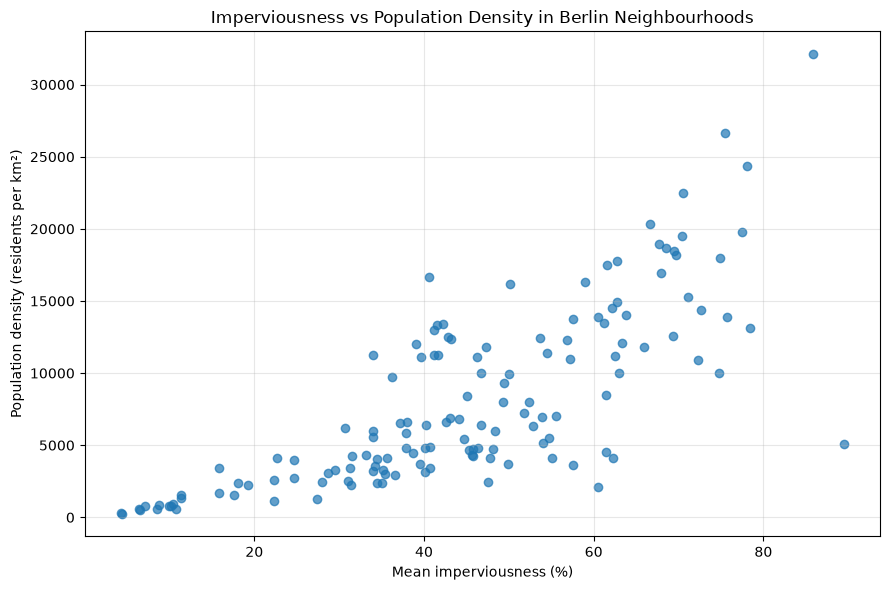

In [39]:
import matplotlib.pyplot as plt

# Keep only neighbourhoods with both indicators available
correlation_data = lor_environment_population[
    ["imperviousness_mean", "population_density_km2"]
].dropna()

# Calculate Pearson correlation
correlation = correlation_data["imperviousness_mean"].corr(
    correlation_data["population_density_km2"],
    method="pearson"
)

print("Number of neighbourhoods:", len(correlation_data))
print("Pearson correlation:", round(correlation, 3))

# Create a scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    correlation_data["imperviousness_mean"],
    correlation_data["population_density_km2"],
    alpha=0.7
)

plt.xlabel("Mean imperviousness (%)")
plt.ylabel("Population density (residents per km²)")
plt.title("Imperviousness vs Population Density in Berlin Neighbourhoods")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
# Check the geometry dataset
print("Geometry shape:", lor_tree_crs.shape)
print("Geometry CRS:", lor_tree_crs.crs)
print("Geometry IDs:", lor_tree_crs["bzr_id"].nunique())

# Check the final analytical dataset
print("Analytical IDs:", lor_environment_population["bzr_id"].nunique())

# Check whether all IDs match
print(
    "Unmatched geometry IDs:",
    len(
        set(lor_tree_crs["bzr_id"])
        - set(lor_environment_population["bzr_id"])
    )
)

Geometry shape: (143, 9)
Geometry CRS: EPSG:3035
Geometry IDs: 143
Analytical IDs: 143
Unmatched geometry IDs: 0


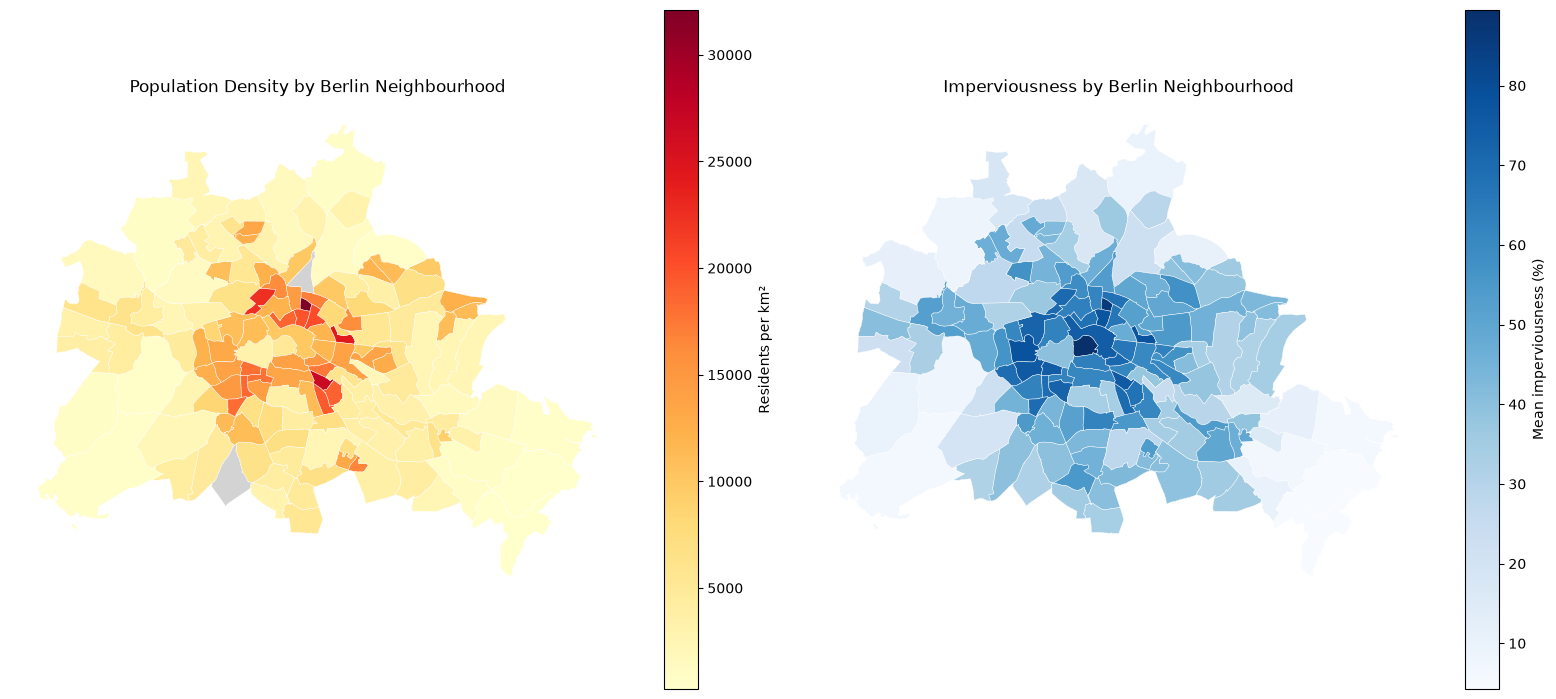

In [44]:
import matplotlib.pyplot as plt

# Join analytical indicators to neighbourhood geometries
lor_map = lor_tree_crs.merge(
    lor_environment_population[
        [
            "bzr_id",
            "population_density_km2",
            "imperviousness_mean"
        ]
    ],
    on="bzr_id",
    how="left",
    validate="one_to_one"
)

# Create two maps
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

# Map 1: Population density
lor_map.plot(
    column="population_density_km2",
    cmap="YlOrRd",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    ax=axes[0],
    missing_kwds={
        "color": "lightgrey",
        "label": "Missing data"
    },
    legend_kwds={
        "label": "Residents per km²",
        "shrink": 0.7
    }
)

axes[0].set_title("Population Density by Berlin Neighbourhood")
axes[0].axis("off")

# Map 2: Imperviousness
lor_map.plot(
    column="imperviousness_mean",
    cmap="Blues",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    ax=axes[1],
    missing_kwds={
        "color": "lightgrey",
        "label": "Missing data"
    },
    legend_kwds={
        "label": "Mean imperviousness (%)",
        "shrink": 0.7
    }
)

axes[1].set_title("Imperviousness by Berlin Neighbourhood")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr

# Calculate Spearman correlation
spearman_corr, spearman_p = spearmanr(
    correlation_data["imperviousness_mean"],
    correlation_data["population_density_km2"]
)

print("Pearson correlation:", round(correlation, 3))
print("Spearman correlation:", round(spearman_corr, 3))
print("Spearman p-value:", spearman_p)

'''
Spearman p value being higher suggests that the relationship is particularly consistent in terms of ranking: neighbourhoods with higher population density generally also rank higher in imperviousness.
The very small p-value provides strong evidence against the hypothesis of no monotonic association, assuming the observations are independent.
'''

Pearson correlation: 0.761
Spearman correlation: 0.802
Spearman p-value: 5.901518439646694e-33


In [46]:
# Calculate correlations separately for each district
district_correlations = (
    lor_environment_population
    .dropna(subset=[
        "imperviousness_mean",
        "population_density_km2"
    ])
    .groupby("bez")
    .apply(
        lambda group: pd.Series({
            "neighbourhoods": len(group),
            "pearson": group["imperviousness_mean"].corr(
                group["population_density_km2"]
            ),
            "spearman": group["imperviousness_mean"].corr(
                group["population_density_km2"],
                method="spearman"
            )
        }),
        include_groups=False
    )
    .reset_index()
)

print(district_correlations.round(3))

                                bez  neighbourhoods  pearson  spearman
0                        01 - Mitte            10.0    0.267     0.067
1     02 - Friedrichshain-Kreuzberg             8.0    0.715     0.524
2                       03 - Pankow            15.0    0.932     0.961
3   04 - Charlottenburg-Wilmersdorf            11.0    0.918     0.918
4                      05 - Spandau             9.0    0.607     0.550
5          06 - Steglitz-Zehlendorf             7.0    0.920     1.000
6         07 - Tempelhof-Schöneberg            15.0    0.821     0.700
7                     08 - Neukölln            12.0    0.633     0.622
8             09 - Treptow-Köpenick            20.0    0.850     0.886
9          10 - Marzahn-Hellersdorf             9.0    0.620     0.683
10                 11 - Lichtenberg            13.0    0.263     0.099
11               12 - Reinickendorf            12.0    0.697     0.601


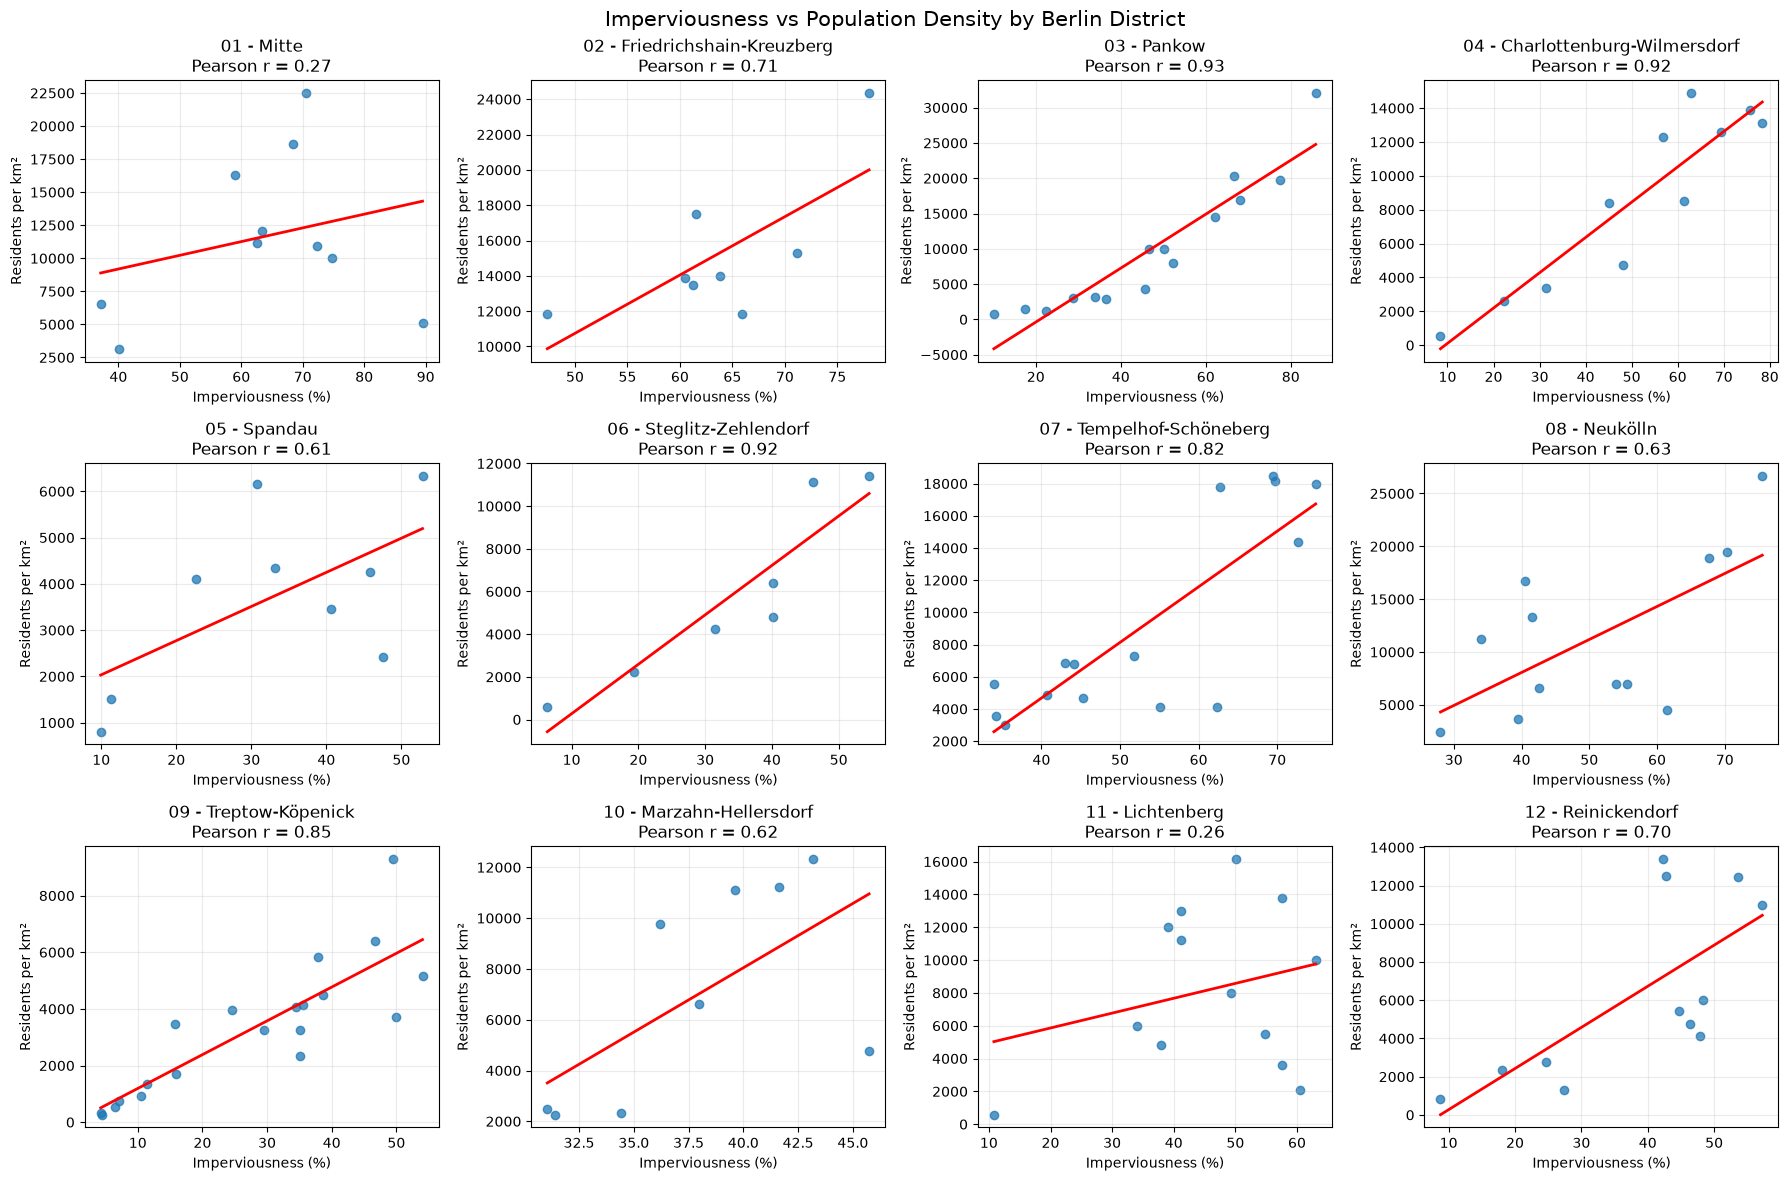

In [49]:
import numpy as np

# Prepare complete observations
plot_data = lor_environment_population.dropna(
    subset=["imperviousness_mean", "population_density_km2"]
)

districts = sorted(plot_data["bez"].unique())

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, district in zip(axes.flat, districts):

    district_data = plot_data[plot_data["bez"] == district]

    x = district_data["imperviousness_mean"]
    y = district_data["population_density_km2"]

    # Scatter plot
    ax.scatter(x, y, alpha=0.75)

    # Calculate and plot linear trend line
    if len(district_data) >= 2 and x.nunique() >= 2:
        slope, intercept = np.polyfit(x, y, 1)

        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        ax.plot(x_line, y_line, color="red", linewidth=2)

    # Calculate Pearson correlation
    r = x.corr(y)

    ax.set_title(f"{district}\nPearson r = {r:.2f}")
    ax.set_xlabel("Imperviousness (%)")
    ax.set_ylabel("Residents per km²")
    ax.grid(alpha=0.25)

plt.suptitle(
    "Imperviousness vs Population Density by Berlin District",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [50]:
# Fit a citywide linear regression
x = correlation_data["imperviousness_mean"]
y = correlation_data["population_density_km2"]

slope, intercept = np.polyfit(x, y, 1)

# Calculate predicted population density
lor_environment_population["predicted_density"] = (
    slope * lor_environment_population["imperviousness_mean"]
    + intercept
)

# Calculate residuals
lor_environment_population["density_residual"] = (
    lor_environment_population["population_density_km2"]
    - lor_environment_population["predicted_density"]
)

# Show neighbourhoods with the largest positive and negative residuals
residuals_sorted = lor_environment_population.dropna(
    subset=["density_residual"]
)

print("Higher population density than predicted:")
display(
    residuals_sorted.nlargest(
        5, "density_residual"
    )[[
        "bzr_name",
        "bez",
        "imperviousness_mean",
        "population_density_km2",
        "density_residual"
    ]]
)

print("Lower population density than predicted:")
display(
    residuals_sorted.nsmallest(
        5, "density_residual"
    )[[
        "bzr_name",
        "bez",
        "imperviousness_mean",
        "population_density_km2",
        "density_residual"
    ]]
)

Higher population density than predicted:


,bzr_name,bez,imperviousness_mean,population_density_km2,density_residual
30,Helmholtzplatz,03 - Pankow,85.858647,32100.375420,13858.945984
79,Reuterstraße,08 - Neukölln,75.533310,26674.498350,10972.232790
86,Gropiusstadt Ost,08 - Neukölln,40.584613,16674.051147,9566.223795
9,Wedding Zentrum,01 - Mitte,70.511322,22515.300323,8048.021061
16,Frankfurter Allee Nord,02 - Friedrichshain-Kreuzberg,78.027249,24361.539179,8045.974608


Lower population density than predicted:


,bzr_name,bez,imperviousness_mean,population_density_km2,density_residual
1,Regierungsviertel,01 - Mitte,89.484086,5104.114961,-14028.867477
129,Rummelsburger Bucht,11 - Lichtenberg,60.527451,2070.784202,-9941.303081
70,Tempelhof Südost,07 - Tempelhof-Schöneberg,62.283428,4143.455002,-8300.454666
81,Köllnische Heide,08 - Neukölln,61.494668,4541.969813,-7707.971421
121,Alt-Hohenschönhausen Nord,11 - Lichtenberg,57.564494,3608.949728,-7674.499403


- Some neighbourhoods have much higher population density than their imperviousness would lead us to predict. Others have much lower population density despite having highly impervious surfaces.
- Gropiusstadt Ost stands out. Its imperviousness is considerably lower than the other neighbourhoods in this group, yet its population density is high
- Regierungsviertel has the highest imperviousness in this list, but relatively low residential population density. This illustrates an important limitation of imperviousness as an indicator: roads, commercial buildings, institutional buildings and other sealed surfaces do not necessarily correspond to residential population.

In [51]:
# Select the five highest and five lowest residuals
outlier_neighbourhoods = pd.concat([
    residuals_sorted.nlargest(5, "density_residual"),
    residuals_sorted.nsmallest(5, "density_residual")
])

# Compare population, imperviousness and green indicators
display(
    outlier_neighbourhoods[
        [
            "bzr_name",
            "bez",
            "population_density_km2",
            "imperviousness_mean",
            "tree_cover_mean",
            "green_natural",
            "density_residual"
        ]
    ].round(2).reset_index(drop=True)
)

,bzr_name,bez,population_density_km2,imperviousness_mean,tree_cover_mean,green_natural,density_residual
0,Helmholtzplatz,03 - Pankow,32100.38,85.86,1.64,3.12,13858.95
1,Reuterstraße,08 - Neukölln,26674.50,75.53,3.28,1.64,10972.23
2,Gropiusstadt Ost,08 - Neukölln,16674.05,40.58,20.12,8.95,9566.22
3,Wedding Zentrum,01 - Mitte,22515.30,70.51,6.45,7.29,8048.02
4,Frankfurter Allee Nord,02 - Friedrichshain-Kreuzberg,24361.54,78.03,2.85,2.64,8045.97
5,Regierungsviertel,01 - Mitte,5104.11,89.48,0.75,4.92,-14028.87
6,Rummelsburger Bucht,11 - Lichtenberg,2070.78,60.53,3.23,2.57,-9941.30
7,Tempelhof Südost,07 - Tempelhof-Schöneberg,4143.46,62.28,7.74,7.17,-8300.45
8,Köllnische Heide,08 - Neukölln,4541.97,61.49,6.95,2.89,-7707.97
9,Alt-Hohenschönhausen Nord,11 - Lichtenberg,3608.95,57.56,5.02,3.14,-7674.50


Certain neighbourhoods show relatively low imperviousness against higher population density (Gropiusstadt Ost for example), while others show high impreviousness mean and low population (Regierungsviertel)

In [52]:
# Select the indicators for comparison
environmental_correlations = lor_environment_population[
    [
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean",
        "green_natural"
    ]
].dropna()

# Calculate Pearson correlation matrix
correlation_matrix = environmental_correlations.corr(
    method="pearson"
)

print(correlation_matrix.round(3))

                        population_density_km2  imperviousness_mean  \
population_density_km2                   1.000                0.761   
imperviousness_mean                      0.761                1.000   
tree_cover_mean                         -0.529               -0.796   
green_natural                           -0.483               -0.760   

                        tree_cover_mean  green_natural  
population_density_km2           -0.529         -0.483  
imperviousness_mean              -0.796         -0.760  
tree_cover_mean                   1.000          0.922  
green_natural                     0.922          1.000  


- Both vegetation indicators are negatively correlated with population density. This suggests that, across Berlin's neighbourhoods, more densely populated areas tend to have less tree cover and less green/natural land. However, the relationship is not perfect, see examples of Gropiusstadt Ost and Regierunsviertel.
- Neighbourhoods with more impervious surfaces generally have lower vegetation indicators.
- High correlation between tree cover and natural areas.



In [53]:
# Calculate Spearman correlation matrix
spearman_matrix = environmental_correlations.corr(
    method="spearman"
)

print(spearman_matrix.round(3))

                        population_density_km2  imperviousness_mean  \
population_density_km2                   1.000                0.802   
imperviousness_mean                      0.802                1.000   
tree_cover_mean                         -0.580               -0.786   
green_natural                           -0.520               -0.710   

                        tree_cover_mean  green_natural  
population_density_km2           -0.580         -0.520  
imperviousness_mean              -0.786         -0.710  
tree_cover_mean                   1.000          0.848  
green_natural                     0.848          1.000  


- positive correlations between pop density/imperviousness and tree coverage/green areas
- negative between pop density and tree cover/natural areas
- strong negative between imperviousness and tree cover, imperviousness and green areas